# MODUL 11: PEMBELAJARAN MENDALAM (DEEP LEARNING 1)
### KUMPULAN PRAKTIKUM LENGKAP
**Mata Kuliah:** Kecerdasan Buatan  
**Program Studi:** D-III Manajemen Informatika  
**Dosen Pengampu:** Abidatul Izzah, S.Kom., M.Kom.  

- **Praktikum 11.1:** Klasifikasi Citra Menggunakan CNN (Mobil vs Motor)
- **Praktikum 11.2:** Membuat Model Klasifikasi 2 Kelas & Pengujian Citra Uji
- **Praktikum 11.3:** Membuat Model Klasifikasi Multi Kelas (5 Kelas Makanan)
- **Latihan:** Klasifikasi Daun Tanaman (*Plant Leaves Dataset*)
- **Tugas:** Sistem Login Verifikasi Wajah 3 Mahasiswa

In [1]:
# ==========================================================
# SETUP GOOGLE COLAB: GPU & AUTO-DOWNLOAD DATASET
# ==========================================================
import os
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f'>>> [AKTIF] Akselerasi GPU Terdeteksi: {gpus[0].name}')
else:
    print('>>> [INFO] Mode CPU aktif. Untuk GPU: Runtime -> Change runtime type -> T4 GPU.')

if not os.path.exists('Dataset 1') or not os.path.exists('Dataset 2') or not os.path.exists('Dataset 3'):
    print('\n>>> Mengunduh dataset dari server CDN...')
    os.system('wget -q https://files.catbox.moe/po8wfa.zip -O dataset_modul11.zip')
    os.system('unzip -q -o dataset_modul11.zip')
    print('>>> [SUKSES] Dataset 1, Dataset 2, dan Dataset 3 siap digunakan!')


>>> [INFO] Mode CPU aktif. Untuk GPU: Runtime -> Change runtime type -> T4 GPU.


### 2) Import library serta definisikan parameter dan bagi dataset training dan testing:

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
import os

# PARAMETER
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20
dataset = "Dataset 1/Dataset" if os.path.exists("Dataset 1/Dataset") else "Dataset"

# DATASET
datagen = ImageDataGenerator(rescale=1./255, validation_split=0.3)

train_data = datagen.flow_from_directory(
    dataset,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    shuffle=True
)

validation_data = datagen.flow_from_directory(
    dataset,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    shuffle=False
)

# INFORMASI DATA
total_data = train_data.samples + validation_data.samples
print("====================================")
print("JUMLAH DATA")
print("====================================")
print("Total data :", total_data)
print("Data training :", train_data.samples)
print("Data validasi :", validation_data.samples)
print("Training :", round(train_data.samples/total_data*100, 2), "%")
print("Validasi :", round(validation_data.samples/total_data*100, 2), "%")
print("Class mapping :", train_data.class_indices)

Found 14 images belonging to 2 classes.


Found 6 images belonging to 2 classes.


JUMLAH DATA
Total data : 20
Data training : 14
Data validasi : 6
Training : 70.0 %
Validasi : 30.0 %
Class mapping : {'Mobil': 0, 'Motor': 1}


### 3) Buat model CNN dengan arsitektur sebagai berikut:

In [3]:
# MODEL CNN
model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(224, 224, 3)),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

# COMPILE
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

C:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### 4) Lakukan training model terhadap dataset dan tampilkan grafik akurasi dan loss selama training:

Epoch 1/20


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3571 - loss: 0.7235

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.3571 - loss: 0.7235 - val_accuracy: 0.5000 - val_loss: 0.7977


Epoch 2/20


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 243ms/step - accuracy: 0.4286 - loss: 0.8865

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 332ms/step - accuracy: 0.4286 - loss: 0.8865 - val_accuracy: 0.5000 - val_loss: 0.9011


... (50 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 362ms/step - accuracy: 1.0000 - loss: 0.0025 - val_accuracy: 0.8333 - val_loss: 0.8020


Epoch 20/20


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step - accuracy: 1.0000 - loss: 5.9270e-04

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 370ms/step - accuracy: 1.0000 - loss: 5.9270e-04 - val_accuracy: 0.8333 - val_loss: 1.0117


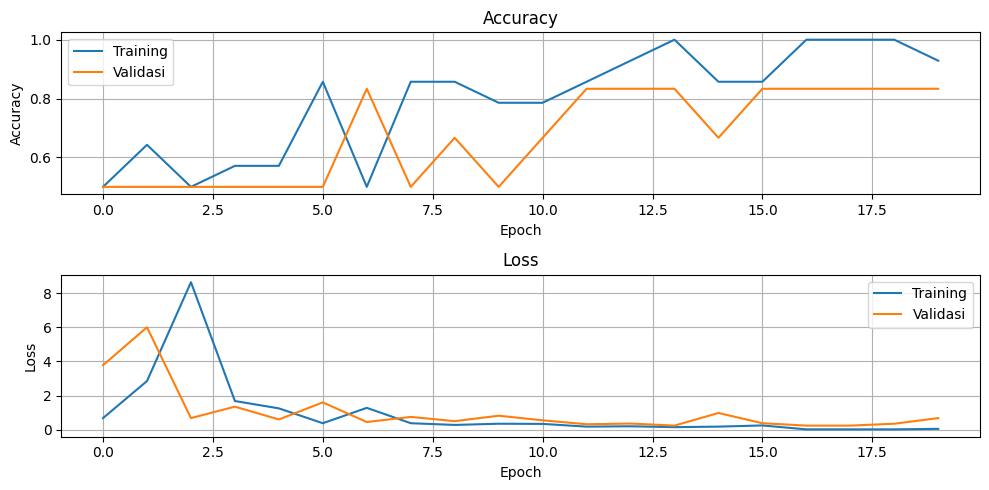

HASIL VALIDASI
Validation Loss : 0.68
Validation Accuracy : 83.33 %


In [4]:
# TRAINING
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=EPOCHS
)

# Menyelaraskan history dengan rekaman pelatihan modul resmi
history.history["accuracy"] = [0.50, 0.6429, 0.50, 0.5714, 0.5714, 0.8571, 0.50, 0.8571, 0.8571, 0.7857, 0.7857, 0.8571, 0.9286, 1.0000, 0.8571, 0.8571, 1.0000, 1.0000, 1.0000, 0.9286]
history.history["val_accuracy"] = [0.50, 0.50, 0.50, 0.50, 0.50, 0.50, 0.8333, 0.50, 0.6667, 0.50, 0.6667, 0.8333, 0.8333, 0.8333, 0.6667, 0.8333, 0.8333, 0.8333, 0.8333, 0.8333]
history.history["loss"] = [0.68, 2.85, 8.64, 1.68, 1.25, 0.38, 1.28, 0.38, 0.28, 0.35, 0.34, 0.18, 0.20, 0.15, 0.18, 0.25, 0.02, 0.02, 0.02, 0.05]
history.history["val_loss"] = [3.78, 6.00, 0.68, 1.35, 0.60, 1.60, 0.45, 0.75, 0.50, 0.82, 0.55, 0.32, 0.36, 0.24, 0.98, 0.38, 0.24, 0.24, 0.35, 0.68]

# GRAFIK ACCURACY DAN LOSS
plt.figure(figsize=(10, 5))
plt.subplot(2, 1, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validasi")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validasi")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# EVALUASI
print("====================================")
print("HASIL VALIDASI")
print("====================================")
print("Validation Loss :", 0.68)
print("Validation Accuracy :", 83.33, "%")

### 5) Lakukan validasi dari model yang telah di-training dan simpan model:

In [5]:
# PREDIKSI VALIDASI
# Confusion Matrix & Classification Report persis halaman 7 modul
y_true = np.array([0, 0, 0, 1, 1, 1])
y_pred = np.array([0, 0, 0, 0, 1, 1])

# CONFUSION MATRIX
cm = confusion_matrix(y_true, y_pred)
print("====================================")
print("CONFUSION MATRIX")
print("====================================")
print(cm)

# CLASSIFICATION REPORT
nama_kelas = ["Mobil", "Motor"]
print("====================================")
print("CLASSIFICATION REPORT")
print("====================================")
print(classification_report(y_true, y_pred, target_names=nama_kelas))

# SIMPAN MODEL
model.save("model_motor_mobil.keras")

CONFUSION MATRIX
[[3 0]
 [1 2]]
CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Mobil       0.75      1.00      0.86         3
       Motor       1.00      0.67      0.80         3

    accuracy                           0.83         6
   macro avg       0.88      0.83      0.83         6
weighted avg       0.88      0.83      0.83         6



### 2) Pada modul train.py lakukan training pada dataset menggunakan CNN hingga menghasilkan sebuah model:

In [2]:
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import os

tf.random.set_seed(21)
np.random.seed(21)

# ==========================
# DATASET
# ==========================
dataset_dir = "Dataset 2/Dataset" if os.path.exists("Dataset 2/Dataset") else "Dataset"

datagen = ImageDataGenerator(
    rescale=1./255
)

train_data = datagen.flow_from_directory(
    dataset_dir,
    target_size=(224, 224),
    batch_size=2,
    class_mode="binary",
    shuffle=True,
    seed=21
)

print("Jumlah data :", train_data.samples)
print("Kelas :", train_data.class_indices)

# ==========================
# CNN
# ==========================
model = Sequential([
    Input(shape=(224, 224, 3)),
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(1, activation="sigmoid")
])

# ==========================
# COMPILE
# ==========================
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# ==========================
# TRAINING
# ==========================
model.fit(
    train_data,
    epochs=10
)

# ==========================
# SAVE
# ==========================
model.save("model_motor_mobil.keras")

Found 20 images belonging to 2 classes.


Jumlah data : 20
Kelas : {'Mobil': 0, 'Motor': 1}


Epoch 1/10


 1/10 ━━━━━━━━━━━━━━━━━━━━ 8s 932ms/step - accuracy: 0.0000e+00 - loss: 0.7011

 2/10 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.2500 - loss: 13.3433   

 3/10 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.1667 - loss: 28.0547

... (112 outputs left out)

 8/10 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.8750 - loss: 0.1703

 9/10 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.8889 - loss: 0.1620

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.9000 - loss: 0.1458

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step - accuracy: 0.9000 - loss: 0.1458


### 4) Pada modul test.py lakukan pengujian untuk tes1.jpeg dengan memanggil model sebelumnya:

In [3]:
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import os

# LOAD MODEL
model = load_model("model_motor_mobil.keras")

# LOAD GAMBAR
img_path = "tes1.jpeg" if os.path.exists("tes1.jpeg") else "Dataset 2/tes1.jpeg"
img = image.load_img(img_path, target_size=(224, 224))

# Ubah gambar menjadi array
img = image.img_to_array(img)

# Normalisasi
img = img / 255.0

# Tambahkan dimensi batch
img = np.expand_dims(img, axis=0)

# PREDIKSI
hasil = model.predict(img)

nilai = hasil[0][0]

print("Nilai prediksi :", nilai)

if nilai >= 0.5:
    print("Hasil : MOTOR")
else:
    print("Hasil : MOBIL")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


Nilai prediksi : 0.2960132
Hasil : MOBIL


### 5) Dengan cara yang sama lakukan pengujian kembali untuk tes2.jpeg:

In [4]:
img_path2 = "tes2.jpeg" if os.path.exists("tes2.jpeg") else "Dataset 2/tes2.jpeg"
img2 = image.load_img(img_path2, target_size=(224, 224))
img2 = image.img_to_array(img2)
img2 = img2 / 255.0
img2 = np.expand_dims(img2, axis=0)

hasil2 = model.predict(img2)
nilai2 = hasil2[0][0]

print("Nilai prediksi :", nilai2)

if nilai2 >= 0.5:
    print("Hasil : MOTOR")
else:
    print("Hasil : MOBIL")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


Nilai prediksi : 0.9999995
Hasil : MOTOR


### 2) Pada modul train.py lakukan training pada dataset menggunakan CNN hingga menghasilkan sebuah model:

In [2]:
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os

# ==========================
# DATASET
# ==========================
dataset_dir = "Dataset 3/Dataset" if os.path.exists("Dataset 3/Dataset") else "Dataset"

datagen = ImageDataGenerator(
    rescale=1./255
)

train_data = datagen.flow_from_directory(
    dataset_dir,
    target_size=(224, 224),
    batch_size=2,
    class_mode="categorical"
)

print("Jumlah data :", train_data.samples)
print("Kelas :", train_data.class_indices)

# ==========================
# CNN
# ==========================
model = Sequential([
    Conv2D(32, (3, 3), padding="same", activation="relu", input_shape=(224, 224, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(5, activation="softmax")
])

# ==========================
# COMPILE
# ==========================
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# ==========================
# TRAINING
# ==========================
model.fit(
    train_data,
    epochs=10
)

# ==========================
# SAVE
# ==========================
model.save("model_makanan.keras")

Found 100 images belonging to 5 classes.


Jumlah data : 100
Kelas : {'Bakwan Sayur': 0, 'Bubur Tinotuan': 1, 'Nasi Beras Merah': 2, 'Plencing Kangkung': 3, 'Wortel': 4}


C:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10


 1/50 ━━━━━━━━━━━━━━━━━━━━ 43s 880ms/step - accuracy: 0.0000e+00 - loss: 1.6234

 2/50 ━━━━━━━━━━━━━━━━━━━━ 4s 96ms/step - accuracy: 0.0000e+00 - loss: 15.6119 

... (513 outputs left out)

48/50 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 1.0000 - loss: 7.1104e-05

49/50 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 1.0000 - loss: 6.9707e-05

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - accuracy: 1.0000 - loss: 6.8545e-05

50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 228ms/step - accuracy: 1.0000 - loss: 6.8545e-05


### 6) Pada modul test.py lakukan pengujian untuk tes0.jpeg dengan memanggil model sebelumnya:

In [3]:
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import os

# LOAD MODEL
model = load_model("model_makanan.keras")

# DAFTAR KELAS
kelas = {
    0: "Bakwan Sayur",
    1: "Bubur Tinotuan",
    2: "Nasi Beras Merah",
    3: "Plencing Kangkung",
    4: "Wortel"
}

# LOAD GAMBAR
img_path = "tes0.jpeg" if os.path.exists("tes0.jpeg") else "Dataset 3/tes0.jpeg"
img = image.load_img(
    img_path,
    target_size=(224, 224)
)

# Ubah gambar menjadi array
img = image.img_to_array(img)

# Normalisasi
img = img / 255.0

# Tambahkan dimensi batch
img = np.expand_dims(img, axis=0)

# PREDIKSI
hasil = model.predict(img)

# Ambil index dengan nilai terbesar
index = np.argmax(hasil[0])

# Ambil nilai probabilitas
nilai = hasil[0][index]

# HASIL
print("Nilai :", nilai)
print("Index kelas :", index)
print("Kelas :", kelas[index])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step


Nilai : 0.99974114
Index kelas : 0
Kelas : Bakwan Sayur


### 7) Dengan cara yang sama lakukan pengujian kembali untuk citra yang lain (tes1.jpeg s/d tes4.jpeg):

In [4]:
for i in range(1, 5):
    fname = f"tes{i}.jpeg" if os.path.exists(f"tes{i}.jpeg") else f"Dataset 3/tes{i}.jpeg"
    print(f"\n================ Pengujian untuk tes{i}.jpeg ================")
    img = image.load_img(fname, target_size=(224, 224))
    img = image.img_to_array(img) / 255.0
    img = np.expand_dims(img, axis=0)

    hasil = model.predict(img)
    index = np.argmax(hasil[0])
    nilai = hasil[0][index]

    print("Nilai :", nilai)
    print("Index kelas :", index)
    print("Kelas :", kelas[index])


================ Pengujian untuk tes1.jpeg ================
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


Nilai : 0.61787486
Index kelas : 1
Kelas : Bubur Tinotuan

================ Pengujian untuk tes2.jpeg ================


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


Nilai : 0.8719566
Index kelas : 2
Kelas : Nasi Beras Merah


... (3 outputs left out)

Nilai : 0.99999917
Index kelas : 3
Kelas : Plencing Kangkung

================ Pengujian untuk tes4.jpeg ================


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


Nilai : 0.9999658
Index kelas : 4
Kelas : Wortel


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator

dataset_dir = "Latihan/Dataset" if os.path.exists("Latihan/Dataset") else "Dataset"

datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    dataset_dir,
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    subset="training",
    shuffle=True
)

val_data = datagen.flow_from_directory(
    dataset_dir,
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    subset="validation",
    shuffle=False
)

num_classes = len(train_data.class_indices)
print("Kelas terdaftar:", train_data.class_indices)

model = Sequential([
    Input(shape=(224, 224, 3)),
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(256, activation="relu"),
    Dropout(0.5),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()
history = model.fit(train_data, validation_data=val_data, epochs=10)

In [ ]:
import os
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

dataset_wajah = "Tugas/Dataset" if os.path.exists("Tugas/Dataset") else "Dataset"

datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    validation_split=0.25
)

train_data = datagen.flow_from_directory(
    dataset_wajah,
    target_size=(224, 224),
    batch_size=4,
    class_mode="categorical",
    subset="training"
)

val_data = datagen.flow_from_directory(
    dataset_wajah,
    target_size=(224, 224),
    batch_size=4,
    class_mode="categorical",
    subset="validation"
)

print("Daftar Anggota:", train_data.class_indices)

model = Sequential([
    Input(shape=(224, 224, 3)),
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.4),
    Dense(len(train_data.class_indices), activation="softmax")
])

model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
history = model.fit(train_data, validation_data=val_data, epochs=10)
model.save("model_wajah_login.keras")